### Import libraries and paths

In [2]:
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", 20)
pd.set_option("display.width", 160)

sns.set_theme(style="whitegrid")

cwd = Path.cwd().resolve()

if (cwd / "data" / "raw").exists():
    PROJECT_ROOT = cwd
elif (cwd.parent / "data" / "raw").exists():
    PROJECT_ROOT = cwd.parent
else:
    raise FileNotFoundError("Project folder not found.")

DATA_DIR = PROJECT_ROOT / "data" / "raw"
TABLE_DIR = PROJECT_ROOT / "outputs" / "tables"
FIGURE_DIR = PROJECT_ROOT / "outputs" / "figures"

TABLE_DIR.mkdir(parents=True, exist_ok=True)
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)

Project root: E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research


### Load original and graph-theoretical features

In [3]:
features = pd.read_csv(
    DATA_DIR / "elliptic_txs_features.csv",
    header=None,
    dtype={0: "string"}
)

num_features = features.shape[1] - 2

original_feature_columns = [
    f"feature_{i}"
    for i in range(1, num_features + 1)
]

features.columns = (
    ["txId", "time_step"]
    + original_feature_columns
)

features["txId"] = features["txId"].str.strip()
features["time_step"] = features["time_step"].astype(int)

graph_data = pd.read_csv(
    TABLE_DIR / "08_graph_features.csv",
    dtype={"txId": "string", "class": "string"}
)

graph_data["txId"] = graph_data["txId"].str.strip()

print("Original features:", features.shape)
print("Graph dataset:", graph_data.shape)

display(graph_data.head())

Original features: (203769, 167)
Graph dataset: (203769, 12)


,txId,time_step,class,class_name,in_degree,out_degree,total_degree,degree_difference,degree_ratio,component_size,pagerank,pagerank_scaled
0,230425980,1,unknown,Unknown,1,1,2,0,1.000000,7880,0.000105,0.829387
1,5530458,1,unknown,Unknown,1,1,2,0,1.000000,7880,0.000130,1.026302
2,232022460,1,unknown,Unknown,1,2,3,1,1.500000,7880,0.000130,1.022974
3,232438397,1,2,Licit,160,1,161,-159,0.012422,7880,0.007200,56.734084
4,230460314,1,unknown,Unknown,2,8,10,6,3.000000,7880,0.000055,0.430029


### Merge original and graph features

In [4]:
research_df = features.merge(
    graph_data.drop(columns=["time_step"]),
    on="txId",
    how="inner",
    validate="one_to_one"
)

assert len(research_df) == len(features)

graph_feature_columns = [
    "in_degree",
    "out_degree",
    "total_degree",
    "degree_difference",
    "degree_ratio",
    "component_size",
    "pagerank_scaled"
]

print("Merged research dataset:", research_df.shape)

print("\nOriginal features:", len(original_feature_columns))
print("Graph features:", len(graph_feature_columns))

print("\nClass distribution:")
print(research_df["class_name"].value_counts())

display(
    research_df[
        ["txId", "time_step", "class_name"]
        + graph_feature_columns
    ].head()
)

Merged research dataset: (203769, 177)

Original features: 165
Graph features: 7

Class distribution:
class_name
Unknown    157205
Licit       42019
Illicit      4545
Name: count, dtype: int64


,txId,time_step,class_name,in_degree,out_degree,total_degree,degree_difference,degree_ratio,component_size,pagerank_scaled
0,230425980,1,Unknown,1,1,2,0,1.000000,7880,0.829387
1,5530458,1,Unknown,1,1,2,0,1.000000,7880,1.026302
2,232022460,1,Unknown,1,2,3,1,1.500000,7880,1.022974
3,232438397,1,Licit,160,1,161,-159,0.012422,7880,56.734084
4,230460314,1,Unknown,2,8,10,6,3.000000,7880,0.430029


### Validate research features

In [5]:
all_model_features = (
    original_feature_columns
    + graph_feature_columns
)

missing_values = (
    research_df[all_model_features]
    .isna()
    .sum()
    .sum()
)

infinite_values = np.isinf(
    research_df[all_model_features].to_numpy(
        dtype=float
    )
).sum()

print("RESEARCH DATA VALIDATION")
print("=" * 50)

print("Total transactions:", len(research_df))
print("Original features:", len(original_feature_columns))
print("Graph features:", len(graph_feature_columns))
print("Missing values:", missing_values)
print("Infinite values:", infinite_values)
print("Duplicate transaction IDs:",
      research_df["txId"].duplicated().sum())

assert missing_values == 0
assert infinite_values == 0
assert research_df["txId"].is_unique

print("\nResearch dataset validation passed.")

RESEARCH DATA VALIDATION
Total transactions: 203769
Original features: 165
Graph features: 7
Missing values: 0
Infinite values: 0
Duplicate transaction IDs: 0

Research dataset validation passed.


### Examine correlations between graph features

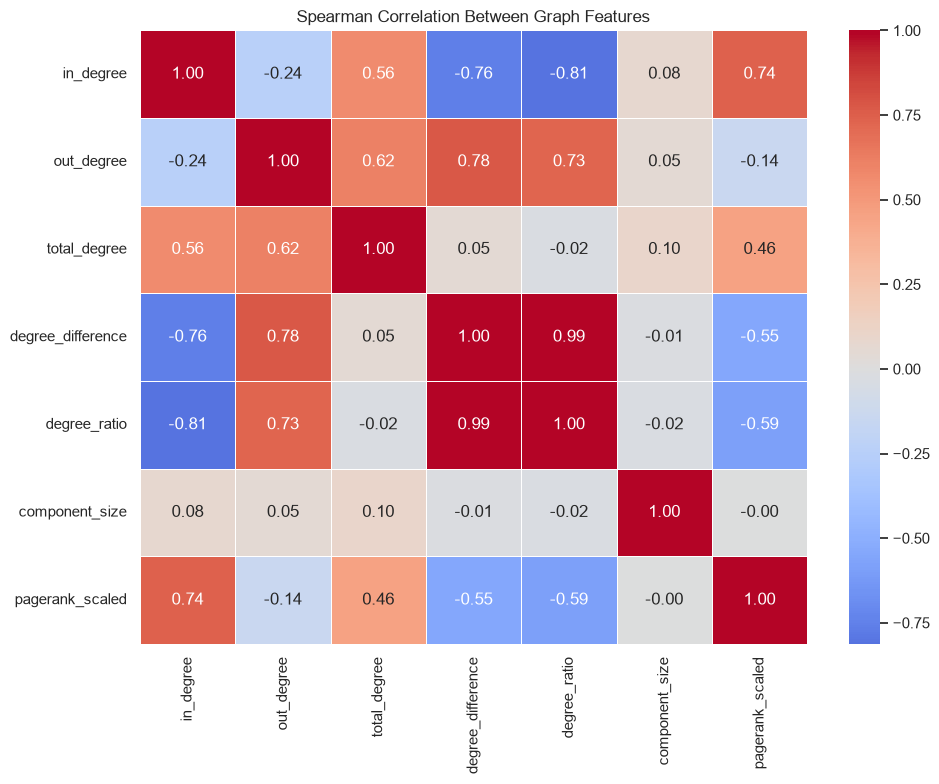

,in_degree,out_degree,total_degree,degree_difference,degree_ratio,component_size,pagerank_scaled
in_degree,1.000,-0.242,0.562,-0.759,-0.813,0.078,0.742
out_degree,-0.242,1.000,0.616,0.778,0.728,0.052,-0.143
total_degree,0.562,0.616,1.000,0.052,-0.022,0.096,0.459
degree_difference,-0.759,0.778,0.052,1.000,0.986,-0.015,-0.549
degree_ratio,-0.813,0.728,-0.022,0.986,1.000,-0.021,-0.592
component_size,0.078,0.052,0.096,-0.015,-0.021,1.000,-0.002
pagerank_scaled,0.742,-0.143,0.459,-0.549,-0.592,-0.002,1.000


In [6]:
correlation_matrix = (
    research_df[graph_feature_columns]
    .corr(method="spearman")
)

plt.figure(figsize=(10, 8))

sns.heatmap(
    correlation_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Spearman Correlation Between Graph Features")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "12_graph_feature_correlations.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

display(correlation_matrix.round(3))

### Compare graph features across classes

In [7]:
labeled_df = research_df[
    research_df["class_name"].isin(
        ["Illicit", "Licit"]
    )
].copy()

class_feature_summary = (
    labeled_df.groupby("class_name")[
        graph_feature_columns
    ]
    .agg(["mean", "median", "std"])
)

display(class_feature_summary)

class_feature_summary.to_csv(
    TABLE_DIR / "09_graph_feature_class_summary.csv"
)

in_degree                  out_degree                  total_degree                  degree_difference  ...           degree_ratio         \
                mean median       std       mean median       std         mean median       std              mean  ...       std         mean median   
class_name                                                                                                         ...                                 
Illicit     1.269967    1.0  7.215218   0.741694    1.0  0.571620     2.011661    1.0  7.177521         -0.528273  ...  7.297631     1.134450    1.0   
Licit       1.909398    1.0  7.122538   1.185821    1.0  3.246769     3.095219    2.0  7.782942         -0.723577  ...  7.872098     1.436643    1.0   

                     component_size                      pagerank_scaled                      
                 std           mean  median          std            mean    median       std  
class_name                                                                                    
Illicit     0.659092    4257.644224  4296.0  1320.702999        0.843513  0.535100  2.390044  
Licit       2.089103    4900.411671  4975.0  1570.545054        1.154378  0.481148  3.092679  

[2 rows x 21 columns]

### Prepare the supervised learning dataset

Only labeled transactions will be used to train and evaluate the models.

Target labels:
$$
y =
\begin{cases}
1 & \text{Illicit transaction}\\
0 & \text{Licit transaction}
\end{cases}
$$

In [8]:
model_df = research_df[
    research_df["class"].isin(["1", "2"])
].copy()

model_df["target"] = (
    model_df["class"] == "1"
).astype(int)

model_df = model_df.sort_values(
    ["time_step", "txId"]
).reset_index(drop=True)

print("SUPERVISED LEARNING DATASET")
print("=" * 50)

print("Total labeled transactions:", len(model_df))

print("Illicit:", (model_df["target"] == 1).sum())
print("Licit:", (model_df["target"] == 0).sum())

print("\nTarget distribution:")
print(model_df["target"].value_counts())

display(
    model_df[
        ["txId", "time_step", "class_name", "target"]
    ].head()
)

SUPERVISED LEARNING DATASET
Total labeled transactions: 46564
Illicit: 4545
Licit: 42019

Target distribution:
target
0    42019
1     4545
Name: count, dtype: int64


,txId,time_step,class_name,target
0,102029923,1,Licit,0
1,102585871,1,Licit,0
2,102664424,1,Licit,0
3,102874126,1,Licit,0
4,10437353,1,Licit,0


### Create a chronological train/validation/test split

Training: Time steps 1–34

Validation: Time steps 35–41

Testing: Time steps 42–49

In [9]:
TRAIN_END = 34
VAL_END = 41

train_df = model_df[
    model_df["time_step"] <= TRAIN_END
].copy()

val_df = model_df[
    (model_df["time_step"] > TRAIN_END)
    & (model_df["time_step"] <= VAL_END)
].copy()

test_df = model_df[
    model_df["time_step"] > VAL_END
].copy()

print("CHRONOLOGICAL DATA SPLIT")
print("=" * 50)

print("Training:", train_df.shape)
print("Validation:", val_df.shape)
print("Testing:", test_df.shape)

print("\nTime-step ranges:")
print("Train:", train_df["time_step"].min(),
      "-", train_df["time_step"].max())

print("Validation:", val_df["time_step"].min(),
      "-", val_df["time_step"].max())

print("Test:", test_df["time_step"].min(),
      "-", test_df["time_step"].max())

assert len(train_df) + len(val_df) + len(test_df) == len(model_df)

assert train_df["time_step"].max() < val_df["time_step"].min()
assert val_df["time_step"].max() < test_df["time_step"].min()

CHRONOLOGICAL DATA SPLIT
Training: (29894, 178)
Validation: (7829, 178)
Testing: (8841, 178)

Time-step ranges:
Train: 1 - 34
Validation: 35 - 41
Test: 42 - 49


### Check class balance across splits

In [10]:
def calculate_split_stats(name, data):

    total = len(data)
    illicit = int(data["target"].sum())
    licit = total - illicit

    return {
        "Split": name,
        "Total": total,
        "Licit": licit,
        "Illicit": illicit,
        "Illicit_Percentage": (
            illicit / total * 100
            if total > 0 else 0
        )
    }


split_summary = pd.DataFrame([
    calculate_split_stats("Train", train_df),
    calculate_split_stats("Validation", val_df),
    calculate_split_stats("Test", test_df)
])

display(split_summary)

split_summary.to_csv(
    TABLE_DIR / "10_temporal_split_summary.csv",
    index=False
)

for name, data in [
    ("Train", train_df),
    ("Validation", val_df),
    ("Test", test_df)
]:
    if data["target"].nunique() < 2:
        print(f"WARNING: {name} contains only one class.")

,Split,Total,Licit,Illicit,Illicit_Percentage
0,Train,29894,26432,3462,11.580919
1,Validation,7829,7154,675,8.621791
2,Test,8841,8433,408,4.614863


### Visualize the chronological split

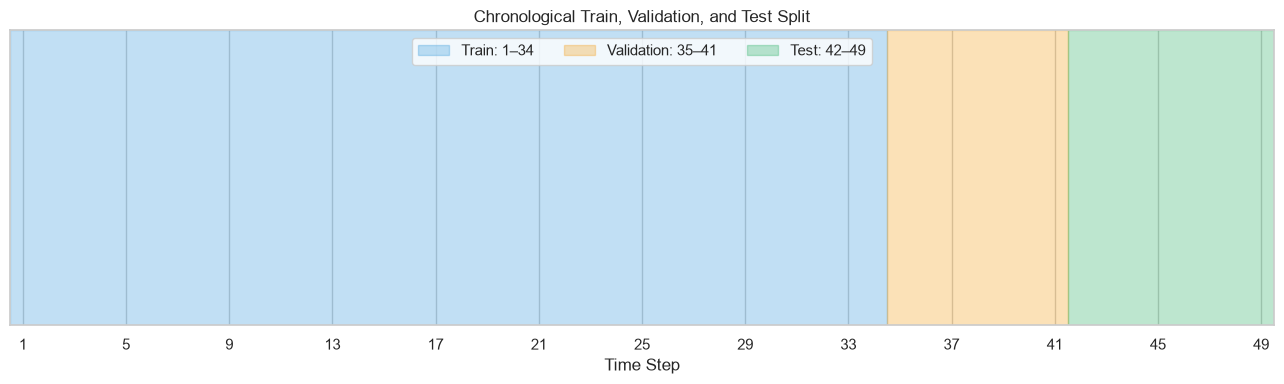

In [11]:
split_colors = {
    "Train": "#3498db",
    "Validation": "#f39c12",
    "Test": "#27ae60"
}

plt.figure(figsize=(13, 4))

for name, start, end in [
    ("Train", 1, TRAIN_END),
    ("Validation", TRAIN_END + 1, VAL_END),
    ("Test", VAL_END + 1, 49)
]:

    plt.axvspan(
        start - 0.5,
        end + 0.5,
        color=split_colors[name],
        alpha=0.3,
        label=f"{name}: {start}–{end}"
    )

plt.xlim(0.5, 49.5)
plt.yticks([])
plt.xticks(range(1, 50, 4))

plt.xlabel("Time Step")
plt.title("Chronological Train, Validation, and Test Split")
plt.legend(loc="upper center", ncol=3)

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "13_temporal_data_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Visualize class imbalance across splits

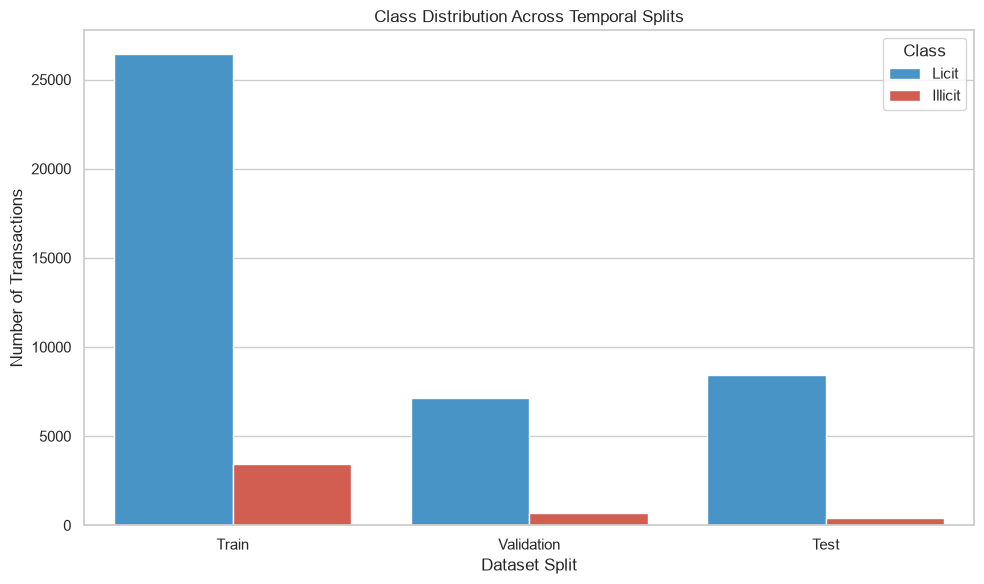

In [12]:
plot_df = split_summary.melt(
    id_vars="Split",
    value_vars=["Licit", "Illicit"],
    var_name="Class",
    value_name="Count"
)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=plot_df,
    x="Split",
    y="Count",
    hue="Class",
    palette={
        "Licit": "#3498db",
        "Illicit": "#e74c3c"
    }
)

plt.title("Class Distribution Across Temporal Splits")
plt.xlabel("Dataset Split")
plt.ylabel("Number of Transactions")

plt.tight_layout()

plt.savefig(
    FIGURE_DIR / "14_class_balance_by_split.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

### Check feature variation

In [13]:
train_feature_variation = (
    train_df[all_model_features]
    .nunique()
)

constant_features = train_feature_variation[
    train_feature_variation <= 1
].index.tolist()

print("FEATURE VARIATION CHECK")
print("=" * 50)

print("Total candidate features:", len(all_model_features))

print("Constant features in training:",
      len(constant_features))

print("\nConstant feature names:")
print(constant_features)

selected_original_features = [
    col for col in original_feature_columns
    if col not in constant_features
]

selected_graph_features = [
    col for col in graph_feature_columns
    if col not in constant_features
]

print("\nSelected original features:",
      len(selected_original_features))

print("Selected graph features:",
      len(selected_graph_features))

FEATURE VARIATION CHECK
Total candidate features: 172
Constant features in training: 0

Constant feature names:
[]

Selected original features: 165
Selected graph features: 7


### Define the three feature groups

In [14]:
FEATURE_GROUPS = {
    "Baseline": selected_original_features,
    "Graph_Only": selected_graph_features,
    "Combined": (
        selected_original_features
        + selected_graph_features
    )
}

feature_group_summary = pd.DataFrame([
    {
        "Experiment": name,
        "Feature_Count": len(columns)
    }
    for name, columns in FEATURE_GROUPS.items()
])

display(feature_group_summary)

feature_group_summary.to_csv(
    TABLE_DIR / "11_feature_group_summary.csv",
    index=False
)

for name, columns in FEATURE_GROUPS.items():
    assert len(columns) > 0
    assert len(columns) == len(set(columns))

print("\nAll experiment feature groups defined.")

,Experiment,Feature_Count
0,Baseline,165
1,Graph_Only,7
2,Combined,172



All experiment feature groups defined.


### Save model-ready datasets

In [15]:
MODEL_DIR = PROJECT_ROOT / "data" / "processed"
MODEL_DIR.mkdir(parents=True, exist_ok=True)

model_columns = (
    ["txId", "time_step", "target"]
    + selected_original_features
    + selected_graph_features
)

train_output = MODEL_DIR / "train.csv"
val_output = MODEL_DIR / "validation.csv"
test_output = MODEL_DIR / "test.csv"

train_df[model_columns].to_csv(
    train_output,
    index=False
)

val_df[model_columns].to_csv(
    val_output,
    index=False
)

test_df[model_columns].to_csv(
    test_output,
    index=False
)

print("Model datasets saved:")
print(train_output)
print(val_output)
print(test_output)

Model datasets saved:
E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\data\processed\train.csv
E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\data\processed\validation.csv
E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\data\processed\test.csv


### Save the experiment configuration

In [16]:
import json

configuration = {
    "research_title": (
        "Graph-Theoretical Feature Analysis for "
        "Illicit Transaction Detection in Bitcoin Networks"
    ),
    "dataset": "Elliptic Bitcoin Transaction Dataset",
    "target": "Illicit = 1, Licit = 0",
    "evaluation_type": "Chronological snapshot classification",
    "train_time_steps": [1, 34],
    "validation_time_steps": [35, 41],
    "test_time_steps": [42, 49],
    "original_features": selected_original_features,
    "graph_features": selected_graph_features,
    "feature_groups": FEATURE_GROUPS,
    "random_state": 42
}

config_path = MODEL_DIR / "experiment_config.json"

with open(config_path, "w", encoding="utf-8") as f:
    json.dump(configuration, f, indent=4)

print("Experiment configuration saved:")
print(config_path)

Experiment configuration saved:
E:\projects\Graph Theory Project\Bitcoin_AML_Graph_Research\data\processed\experiment_config.json


### Final validation

In [17]:
print("=" * 60)
print("NOTEBOOK 03 - FINAL VALIDATION")
print("=" * 60)

checks = {
    "Research dataset contains all transactions": (
        len(research_df) == 203769
    ),
    "Original feature count correct": (
        len(original_feature_columns) == 165
    ),
    "No missing model features": (
        research_df[all_model_features].isna().sum().sum() == 0
    ),
    "All labeled transactions included": (
        len(model_df) == 46564
    ),
    "Chronological split has no overlap": (
        train_df["time_step"].max()
        < val_df["time_step"].min()
        < test_df["time_step"].min()
    ),
    "All splits contain both classes": all(
        data["target"].nunique() == 2
        for data in [train_df, val_df, test_df]
    ),
    "All model datasets saved": all(
        path.exists()
        for path in [train_output, val_output, test_output]
    ),
    "Experiment configuration saved": (
        config_path.exists()
    )
}

for name, passed in checks.items():
    print(f"{'PASS' if passed else 'CHECK'}: {name}")

if all(checks.values()):
    print("\nNotebook 03 completed successfully!")
else:
    print("\nReview flagged checks before continuing.")
    

NOTEBOOK 03 - FINAL VALIDATION
PASS: Research dataset contains all transactions
PASS: Original feature count correct
PASS: No missing model features
PASS: All labeled transactions included
PASS: Chronological split has no overlap
PASS: All splits contain both classes
PASS: All model datasets saved
PASS: Experiment configuration saved

Notebook 03 completed successfully!
